# Stage 11 — CW-L2 Local Graph-Affinity Fusion Investigation

**Focused experiment only.** This does not retrain the CNN or DGI-GCN, regenerate adversarial attacks, or rerun Stage 8.

## Research question
Can a second graph-related signal — the mean cosine affinity of a sample's CNN feature to its 10 nearest **clean training** features — complement the existing DGI-GCN Euclidean anomaly score for CW-L2?

### Signals
1. Existing Stage 8 Euclidean anomaly score (unchanged).
2. Local clean-neighbour affinity: mean cosine similarity to the 10 nearest clean-training CNN feature vectors. This is a local graph-neighbourhood consistency signal; it is not a replacement for the DGI-GCN score.

A two-feature logistic-regression fusion model is fitted on **validation samples only** and evaluated once on the held-out test samples. The test set is not used for fitting, feature scaling, or threshold selection. We also report each signal independently.

This is an exploratory, separately evaluated extension. It must not be described as part of the original DGI-GCN method unless its test performance supports that claim and the manuscript methodology is revised.


## Step 1 — Upload four existing ZIP files

Upload these existing files:
- `Stage4_CNN_Outputs.zip` — frozen CNN checkpoint and clean CNN features.
- `Stage5_Graph_Outputs.zip` — clean graph node features and split masks.
- `Stage7_Final_Corrected_Outputs.zip` — saved CW-L2 adversarial images and metadata.
- `Stage8_Corrected_Outputs.zip` — existing DGI-GCN anomaly scores.

No Stage 6 ZIP is needed. No Stage 9 or Stage 10 ZIP is needed.


In [1]:
from google.colab import files
uploaded = files.upload()

import os, zipfile, glob, json, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, confusion_matrix, precision_score,
                             recall_score, f1_score, accuracy_score)

def pick_zip(keyword):
    matches=[f for f in uploaded if keyword.lower() in f.lower() and f.lower().endswith(".zip")]
    if len(matches)!=1:
        raise FileNotFoundError(f"Expected exactly one uploaded ZIP containing '{keyword}', found {matches}")
    return matches[0]

zip_map={
    "Stage4":pick_zip("stage4"),
    "Stage5":pick_zip("stage5"),
    "Stage7":pick_zip("stage7"),
    "Stage8":pick_zip("stage8")
}
roots={}
for key,zp in zip_map.items():
    root=f"/content/stage11_{key.lower()}"
    os.makedirs(root,exist_ok=True)
    with zipfile.ZipFile(zp) as zf:
        zf.extractall(root)
    roots[key]=root
    print(key, "extracted:", zp)


Saving Stage4_CNN_Outputs.zip to Stage4_CNN_Outputs.zip
Saving Stage5_Graph_Outputs.zip to Stage5_Graph_Outputs.zip
Saving Stage7_Final_Corrected_Outputs.zip to Stage7_Final_Corrected_Outputs.zip
Saving Stage8_Corrected_Outputs.zip to Stage8_Corrected_Outputs.zip
Stage4 extracted: Stage4_CNN_Outputs.zip
Stage5 extracted: Stage5_Graph_Outputs.zip
Stage7 extracted: Stage7_Final_Corrected_Outputs.zip
Stage8 extracted: Stage8_Corrected_Outputs.zip


## Step 2 — Load frozen clean features, split masks and existing Stage 8 scores

In [2]:
def find_file(root, filename):
    found=list(Path(root).rglob(filename))
    if len(found)!=1:
        raise FileNotFoundError(f"Expected one {filename} in {root}; found {len(found)}")
    return found[0]

with np.load(find_file(roots["Stage5"],"graph_node_features_and_masks.npz"),allow_pickle=False) as z:
    X_clean=z["node_features"].astype(np.float32)
    labels=z["labels"].astype(int)
    train_mask=z["train_mask"].astype(bool)
    val_mask=z["validation_mask"].astype(bool)
    test_mask=z["test_mask"].astype(bool)

with np.load(find_file(roots["Stage4"],"cnn_embeddings_128d.npz"),allow_pickle=False) as z:
    stage4_train_idx=z["train_indices"].astype(int)
    stage4_val_idx=z["validation_indices"].astype(int)
    stage4_test_idx=z["test_indices"].astype(int)

assert X_clean.shape==(6400,128)
train_idx=np.where(train_mask)[0]
val_idx=np.where(val_mask)[0]
test_idx=np.where(test_mask)[0]
assert np.array_equal(np.sort(train_idx),np.sort(stage4_train_idx))
assert np.array_equal(np.sort(val_idx),np.sort(stage4_val_idx))
assert np.array_equal(np.sort(test_idx),np.sort(stage4_test_idx))

score_path=find_file(roots["Stage8"],"stage8_anomaly_scores.csv")
scores=pd.read_csv(score_path)
scores=scores[(scores["attack"]=="CW_L2")].copy()
scores["node_index"]=scores["node_index"].astype(int)
scores["anomaly_score"]=pd.to_numeric(scores["anomaly_score"],errors="coerce")
scores["attack_success"]=scores["attack_success"].astype(str).str.lower().isin(["true","1","yes"])
scores=scores.dropna(subset=["anomaly_score"])
print("Clean features:",X_clean.shape,"| train/validation/test:",len(train_idx),len(val_idx),len(test_idx))
print("CW-L2 Stage 8 score rows:",len(scores))


Clean features: (6400, 128) | train/validation/test: 4480 960 960
CW-L2 Stage 8 score rows: 11788


## Step 3 — Load the frozen CNN and extract features for saved CW-L2 adversarial images

Only forward inference is performed. Model weights are not updated. The architecture below matches the Stage 4/Stage 8 CNN definition.

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")

class AlzheimerCNN(nn.Module):
    def __init__(self,num_classes=4,embedding_dim=128,dropout=0.5):
        super().__init__()
        self.features=nn.Sequential(
            nn.Conv2d(1,32,3,padding=1),nn.ReLU(inplace=True),nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1),nn.ReLU(inplace=True),nn.MaxPool2d(2),
            nn.Conv2d(64,128,3,padding=1),nn.ReLU(inplace=True),nn.MaxPool2d(2),
            nn.Conv2d(128,256,3,padding=1),nn.ReLU(inplace=True),nn.MaxPool2d(2))
        self.global_pool=nn.AdaptiveAvgPool2d((1,1))
        self.embedding=nn.Linear(256,embedding_dim)
        self.embedding_activation=nn.ReLU(inplace=True)
        self.dropout=nn.Dropout(p=dropout)
        self.classifier=nn.Linear(embedding_dim,num_classes)
    def forward(self,x,return_embedding=False):
        x=self.features(x); x=self.global_pool(x); x=torch.flatten(x,1)
        z=self.embedding_activation(self.embedding(x))
        logits=self.classifier(self.dropout(z))
        return (logits,z) if return_embedding else logits

ckpt_path=find_file(roots["Stage4"],"best_alzheimer_cnn.pth")
ckpt=torch.load(ckpt_path,map_location=DEVICE,weights_only=False)
class_names=ckpt.get("class_names",["Mild Demented","Moderate Demented","Non-Demented","Very Mild Demented"])
cnn=AlzheimerCNN(num_classes=len(class_names)).to(DEVICE)
cnn.load_state_dict(ckpt["model_state_dict"])
cnn.eval()

def get_cnn_features(images,batch_size=64):
    out=[]
    with torch.no_grad():
        for st in range(0,len(images),batch_size):
            xb=torch.tensor(images[st:st+batch_size],dtype=torch.float32,device=DEVICE)
            _,z=cnn(xb,return_embedding=True)
            out.append(z.cpu().numpy().astype(np.float32))
    return np.concatenate(out,axis=0) if out else np.empty((0,128),np.float32)

print("Frozen CNN loaded on",DEVICE)


Frozen CNN loaded on cuda


## Step 4 — Compute local affinity to the clean training reference graph

For a query feature, local affinity is the average cosine similarity to its 10 nearest clean **training** feature vectors. The query's own clean feature is not in the training reference set for validation/test queries. This makes the reference consistent for clean validation/test samples and their adversarial counterparts.

The Stage 5 features are the clean CNN feature vectors used to build the original graph. Adversarial features are extracted with the frozen Stage 4 CNN.


In [4]:
K=10
X_train=X_clean[train_idx]
X_train_unit=X_train/np.maximum(np.linalg.norm(X_train,axis=1,keepdims=True),1e-12)
nn_clean=NearestNeighbors(n_neighbors=K,metric="cosine",algorithm="brute",n_jobs=-1)
nn_clean.fit(X_train_unit)

def local_affinity(query_features):
    q=np.asarray(query_features,dtype=np.float32)
    q_unit=q/np.maximum(np.linalg.norm(q,axis=1,keepdims=True),1e-12)
    distances,neighbor_ids=nn_clean.kneighbors(q_unit)
    similarities=np.clip(1.0-distances,-1.0,1.0)
    return similarities.mean(axis=1).astype(np.float32)

# Validation/test clean features, queried against clean training reference.
clean_affinity={}
for split,ids in [("validation",val_idx),("test",test_idx)]:
    clean_affinity[split]=local_affinity(X_clean[ids])
    print(split,"clean local-affinity mean:",float(clean_affinity[split].mean()))

# Load CW-L2 correct-only records and compute adversarial CNN embeddings.
adv_records={}
for split in ["validation","test"]:
    fname=f"{split}_CW_L2_correct_only.npz"
    p=find_file(roots["Stage7"],fname)
    with np.load(p,allow_pickle=False) as z:
        rec={k:z[k] for k in z.files}
    req=["indices","adversarial_images","labels","clean_predictions","adversarial_predictions","attack_success"]
    miss=[k for k in req if k not in rec]
    if miss: raise KeyError(f"{fname} missing keys {miss}")
    ids=rec["indices"].astype(int)
    assert np.isin(ids, val_idx if split=="validation" else test_idx).all()
    assert np.array_equal(rec["attack_success"].astype(bool),
                          rec["adversarial_predictions"].astype(int)!=rec["labels"].astype(int))
    assert np.all(rec["clean_predictions"].astype(int)==rec["labels"].astype(int))
    adv_features=get_cnn_features(rec["adversarial_images"].astype(np.float32))
    rec["adv_features"]=adv_features
    rec["adv_local_affinity"]=local_affinity(adv_features)
    rec["indices"]=ids
    adv_records[split]=rec
    print(split,"CW-L2 n:",len(ids),"successful:",int(rec["attack_success"].sum()))


validation clean local-affinity mean: 0.9963753819465637
test clean local-affinity mean: 0.9967038631439209
validation CW-L2 n: 798 successful: 798
test CW-L2 n: 793 successful: 793


## Step 5 — Join local-affinity features to Stage 8 scores by original node index

Only validation and test sets are used. Every clean/adversarial score row must match its original node index. A mismatch stops the notebook.

In [5]:
def build_split_table(split):
    rec=adv_records[split]
    ids=rec["indices"]
    clean_ids=val_idx if split=="validation" else test_idx
    clean_aff_map=dict(zip(clean_ids,clean_affinity[split]))
    adv_aff_map=dict(zip(ids,rec["adv_local_affinity"]))
    sub=scores[scores["split"].str.lower()==split].copy()
    clean=sub[sub["sample_type"]=="clean_paired"].copy()
    adv=sub[sub["sample_type"]=="adversarial"].copy()
    clean=clean[clean["node_index"].isin(clean_aff_map)]
    adv=adv[adv["node_index"].isin(adv_aff_map)]
    if clean["node_index"].duplicated().any() or adv["node_index"].duplicated().any():
        raise ValueError("Duplicate score rows per node index.")
    clean["local_affinity"]=clean["node_index"].map(clean_aff_map)
    adv["local_affinity"]=adv["node_index"].map(adv_aff_map)
    adv=adv[adv["attack_success"]]
    clean["y"]=0; adv["y"]=1
    out=pd.concat([clean,adv],ignore_index=True)
    if out["local_affinity"].isna().any():
        raise ValueError(f"Missing local affinity values in {split}.")
    return out[["split","node_index","sample_type","y","anomaly_score","local_affinity"]]

val_df=build_split_table("validation")
test_df=build_split_table("test")
print("Validation rows:",len(val_df),"Test rows:",len(test_df))
display(pd.concat([val_df.assign(part="validation"),test_df.assign(part="test")])
        .groupby(["part","y"])[["anomaly_score","local_affinity"]].agg(["mean","std"]).round(4))


Validation rows: 1596 Test rows: 1586


anomaly_score         local_affinity        
                      mean     std           mean     std
part       y                                             
test       0        1.8583  0.7632         0.9973  0.0042
           1        1.5273  0.2498         0.9922  0.0090
validation 0        1.8919  0.7798         0.9971  0.0051
           1        1.5563  0.2737         0.9920  0.0092

## Step 6 — Compare individual signals and validation-fitted fusion

The two individual signals are evaluated separately. A logistic-regression fusion model is then fitted on validation data only, using standardized features. Its probability threshold is fixed at 0.5 before the test evaluation. No test-set tuning is performed.

In [6]:
def metric_pack(y,score,threshold=None):
    auc=roc_auc_score(y,score)
    if threshold is None:
        # A fixed 0.5 probability threshold for the fusion output.
        threshold=0.5
    pred=(np.asarray(score)>threshold).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return {"AUC":float(auc),"threshold":float(threshold),"TN":int(tn),"FP":int(fp),"FN":int(fn),"TP":int(tp),
            "precision":float(precision_score(y,pred,zero_division=0)),
            "recall":float(recall_score(y,pred,zero_division=0)),
            "F1":float(f1_score(y,pred,zero_division=0)),
            "accuracy":float(accuracy_score(y,pred)),
            "FPR":float(fp/(fp+tn)) if (fp+tn) else float("nan")}

y_val=val_df["y"].to_numpy()
y_test=test_df["y"].to_numpy()

# Direction of Euclidean anomaly score is already defined: larger means more anomalous.
baseline_val=metric_pack(y_val,val_df["anomaly_score"].to_numpy(),
                         threshold=float(np.percentile(val_df[val_df.y==0]["anomaly_score"],95)))
baseline_test=metric_pack(y_test,test_df["anomaly_score"].to_numpy(),
                          threshold=baseline_val["threshold"])

# Local affinity direction is learned on validation only; lower affinity may indicate weaker
# connection to the clean training neighbourhood.
aff_scaler=StandardScaler()
aff_val_z=aff_scaler.fit_transform(val_df[["local_affinity"]])
aff_test_z=aff_scaler.transform(test_df[["local_affinity"]])
aff_model=LogisticRegression(C=1.0,max_iter=2000,class_weight="balanced",random_state=42)
aff_model.fit(aff_val_z,y_val)
aff_val_prob=aff_model.predict_proba(aff_val_z)[:,1]
aff_test_prob=aff_model.predict_proba(aff_test_z)[:,1]
aff_val_metrics=metric_pack(y_val,aff_val_prob)
aff_test_metrics=metric_pack(y_test,aff_test_prob)

# Two-signal fusion: standardize both signals on validation only.
fusion_scaler=StandardScaler()
Xv=fusion_scaler.fit_transform(val_df[["anomaly_score","local_affinity"]])
Xt=fusion_scaler.transform(test_df[["anomaly_score","local_affinity"]])
fusion_model=LogisticRegression(C=1.0,max_iter=2000,class_weight="balanced",random_state=42)
fusion_model.fit(Xv,y_val)
fusion_val_prob=fusion_model.predict_proba(Xv)[:,1]
fusion_test_prob=fusion_model.predict_proba(Xt)[:,1]
fusion_val_metrics=metric_pack(y_val,fusion_test_prob if False else fusion_val_prob)
fusion_test_metrics=metric_pack(y_test,fusion_test_prob)

comparison=pd.DataFrame([
    {"method":"Euclidean anomaly score only","split":"validation",**baseline_val},
    {"method":"Euclidean anomaly score only","split":"test",**baseline_test},
    {"method":"Local clean-neighbour affinity only","split":"validation",**aff_val_metrics},
    {"method":"Local clean-neighbour affinity only","split":"test",**aff_test_metrics},
    {"method":"Validation-fitted two-signal fusion","split":"validation",**fusion_val_metrics},
    {"method":"Validation-fitted two-signal fusion","split":"test",**fusion_test_metrics}
])
display(comparison.round(4))
print("Fusion coefficients [anomaly_score, local_affinity]:",fusion_model.coef_.ravel())


,method,split,AUC,threshold,TN,FP,FN,TP,precision,recall,F1,accuracy,FPR
0,Euclidean anomaly score only,validation,0.4210,3.6397,758,40,798,0,0.0000,0.0000,0.0000,0.4749,0.0501
1,Euclidean anomaly score only,test,0.4261,3.6397,766,27,793,0,0.0000,0.0000,0.0000,0.4830,0.0340
2,Local clean-neighbour affinity only,validation,0.8124,0.5000,667,131,363,435,0.7686,0.5451,0.6378,0.6905,0.1642
3,Local clean-neighbour affinity only,test,0.8178,0.5000,672,121,384,409,0.7717,0.5158,0.6183,0.6816,0.1526
4,Validation-fitted two-signal fusion,validation,0.8041,0.5000,565,233,204,594,0.7183,0.7444,0.7311,0.7262,0.2920
5,Validation-fitted two-signal fusion,test,0.8140,0.5000,557,236,208,585,0.7125,0.7377,0.7249,0.7201,0.2976


Fusion coefficients [anomaly_score, local_affinity]: [-0.86274755 -1.57625826]


## Step 7 — Review the score distributions and validation-fitted model

A successful result requires improved held-out test AUC and a sensible false-positive/false-negative trade-off, not merely a higher validation score. If the fusion model fails to improve test performance, we reject it and retain the original detector with its CW-L2 limitation.

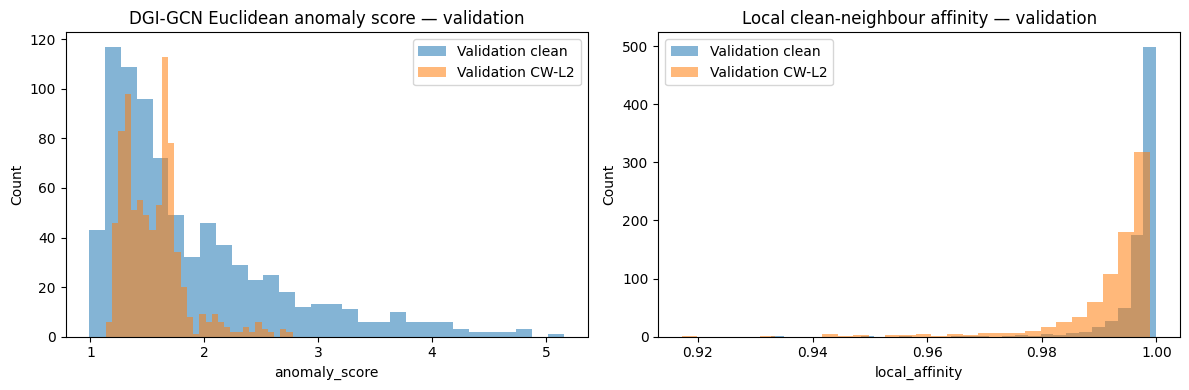

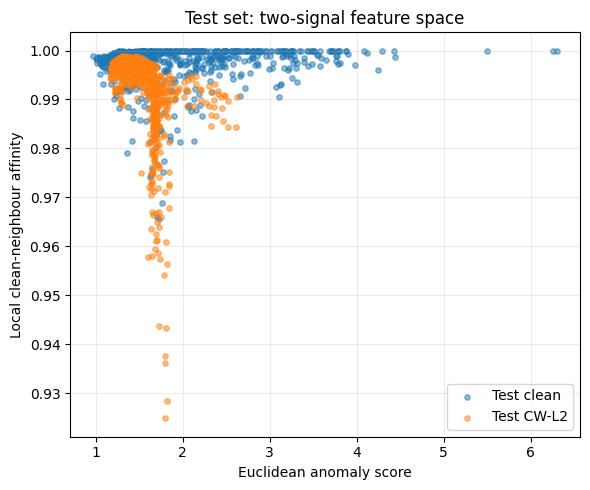

In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,col,title in zip(axes,["anomaly_score","local_affinity"],["DGI-GCN Euclidean anomaly score","Local clean-neighbour affinity"]):
    ax.hist(val_df.loc[val_df.y==0,col],bins=30,alpha=.55,label="Validation clean")
    ax.hist(val_df.loc[val_df.y==1,col],bins=30,alpha=.55,label="Validation CW-L2")
    ax.set_title(title+" — validation")
    ax.set_xlabel(col); ax.set_ylabel("Count"); ax.legend()
plt.tight_layout(); plt.show()

plt.figure(figsize=(6,5))
plt.scatter(test_df.loc[test_df.y==0,"anomaly_score"],test_df.loc[test_df.y==0,"local_affinity"],s=15,alpha=.5,label="Test clean")
plt.scatter(test_df.loc[test_df.y==1,"anomaly_score"],test_df.loc[test_df.y==1,"local_affinity"],s=15,alpha=.5,label="Test CW-L2")
plt.xlabel("Euclidean anomaly score")
plt.ylabel("Local clean-neighbour affinity")
plt.title("Test set: two-signal feature space")
plt.legend(); plt.grid(True,alpha=.25); plt.tight_layout(); plt.show()


## Step 8 — Export Stage 11 evidence

The output ZIP includes the paired data, validation-fitted model coefficients, test metrics and diagnostic plots. Do not replace the original Stage 8/9/10 results with this exploratory fusion result until we review the held-out test outcome and methodological implications.

In [8]:
out="/content/Stage11_CW_L2_Investigation_Outputs"
os.makedirs(out,exist_ok=True)
comparison.to_csv(os.path.join(out,"stage11_signal_and_fusion_metrics.csv"),index=False)
val_df.to_csv(os.path.join(out,"stage11_validation_features.csv"),index=False)
test_df.to_csv(os.path.join(out,"stage11_test_features.csv"),index=False)

model_info={
    "purpose":"Exploratory CW-L2 detection enhancement using local clean-neighbour cosine affinity",
    "existing_signal":"Stage 8 DGI-GCN Euclidean anomaly score; unchanged",
    "second_signal":"Mean cosine similarity of frozen CNN feature to 10 nearest clean training features",
    "fusion_model":"StandardScaler fitted on validation + LogisticRegression(C=1.0,class_weight='balanced',random_state=42)",
    "fit_data":"Validation only",
    "test_used_for_fit_or_tuning":False,
    "fusion_probability_threshold":0.5,
    "fusion_coefficients_anomaly_score_then_local_affinity":[float(x) for x in fusion_model.coef_.ravel()],
    "fusion_intercept":float(fusion_model.intercept_[0]),
    "clean_training_reference_count":int(len(train_idx)),
    "k_neighbours":K,
    "cnn_weights_updated":False,
    "dgi_gcn_weights_updated":False,
    "attacks_regenerated":False,
    "warning":"Exploratory extension. Report as successful only if held-out test performance supports it; it is not part of the original DGI-GCN method."
}
with open(os.path.join(out,"stage11_method_config.json"),"w") as f: json.dump(model_info,f,indent=2)

# Save test feature-space plot.
plt.figure(figsize=(6,5))
plt.scatter(test_df.loc[test_df.y==0,"anomaly_score"],test_df.loc[test_df.y==0,"local_affinity"],s=15,alpha=.5,label="Test clean")
plt.scatter(test_df.loc[test_df.y==1,"anomaly_score"],test_df.loc[test_df.y==1,"local_affinity"],s=15,alpha=.5,label="Test CW-L2")
plt.xlabel("Euclidean anomaly score"); plt.ylabel("Local clean-neighbour affinity")
plt.title("Stage 11 test feature space"); plt.legend(); plt.grid(True,alpha=.25); plt.tight_layout()
plt.savefig(os.path.join(out,"stage11_test_feature_space.png"),dpi=200); plt.close()

zip_out="/content/Stage11_CW_L2_Investigation_Outputs.zip"
with zipfile.ZipFile(zip_out,"w",zipfile.ZIP_DEFLATED) as z:
    for root,_,names in os.walk(out):
        for name in names:
            full=os.path.join(root,name); z.write(full,arcname=os.path.relpath(full,out))
print("Created:",zip_out)
files.download(zip_out)


Created: /content/Stage11_CW_L2_Investigation_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>